# Data Exploration: Amazon Product Dataset 2020

Covers task backlog §1.1 "Acquisition & Exploration": field coverage/nulls per column, price
distribution, duplicate check, and category distribution (to confirm the demo category slice).

Dataset: [`promptcloud/amazon-product-dataset-2020`](https://www.kaggle.com/datasets/promptcloud/amazon-product-dataset-2020) (Kaggle, CC0).

In [1]:
# !pip install pandas matplotlib numpy

## How this data was obtained

```python
import kagglehub
path = kagglehub.dataset_download("promptcloud/amazon-product-dataset-2020")
```

No Kaggle API credentials were needed. It's a public, anonymously-downloadable dataset. The
extracted CSV is committed at `Data/sdf/marketing_sample_for_amazon_com-ecommerce__20200101_20200131__10k_data.csv`
(see [Data/README.md](../../Data/README.md) for the full provenance note), which is what
`CSV_PATH` below points to.

## Setup

In [2]:
import os
import sys

import pandas as pd

# Path to the raw CSV, relative to the repo root (this notebook lives in Code/1. Data Pipeline & Indexing/).
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
CSV_PATH = os.path.join(
    REPO_ROOT,
    "Data",
    "sdf",
    "marketing_sample_for_amazon_com-ecommerce__20200101_20200131__10k_data.csv",
)
OUTPUT_DIR = os.path.join(os.getcwd(), "processed")
COVERAGE_CSV = os.path.join(OUTPUT_DIR, "column_coverage.csv")

# Columns confirmed to be recommended demo-category candidates in the task backlog.
CANDIDATE_CATEGORIES = ["Home & Kitchen", "Sports & Outdoors", "Household", "Cleaning"]


def load_data(path: str) -> pd.DataFrame:
    if not os.path.exists(path):
        sys.exit(
            f"Could not find the dataset at:\n  {path}\n\n"
            "Download it first, e.g.:\n"
            "  import kagglehub\n"
            '  kagglehub.dataset_download("promptcloud/amazon-product-dataset-2020")\n'
            "and place the extracted CSV under Data/sdf/, or update CSV_PATH."
        )
    return pd.read_csv(path)


print("Reading from:", CSV_PATH)
df = load_data(CSV_PATH)
df.head()

Reading from: /Users/pareeyaporn/Desktop/ADSP 32028 Applied Generative AI - Agents and Multimodal Intelligence/Project/Data/sdf/marketing_sample_for_amazon_com-ecommerce__20200101_20200131__10k_data.csv


,Uniq Id,Product Name,Brand Name,Asin,Category,Upc Ean Code,List Price,Selling Price,Quantity,Model Number,...,Product Url,Stock,Product Details,Dimensions,Color,Ingredients,Direction To Use,Is Amazon Seller,Size Quantity Variant,Product Description
0,4c69b61db1fc16e7013b43fc926e502d,"DB Longboards CoreFlex Crossbow 41"" Bamboo Fib...",NaN,NaN,Sports & Outdoors | Outdoor Recreation | Skate...,NaN,NaN,$237.68,NaN,NaN,...,https://www.amazon.com/DB-Longboards-CoreFlex-...,NaN,NaN,NaN,NaN,NaN,NaN,Y,NaN,NaN
1,66d49bbed043f5be260fa9f7fbff5957,"Electronic Snap Circuits Mini Kits Classpack, ...",NaN,NaN,Toys & Games | Learning & Education | Science ...,NaN,NaN,$99.95,NaN,55324,...,https://www.amazon.com/Electronic-Circuits-Cla...,NaN,NaN,NaN,NaN,NaN,NaN,Y,NaN,NaN
2,2c55cae269aebf53838484b0d7dd931a,3Doodler Create Flexy 3D Printing Filament Ref...,NaN,NaN,Toys & Games | Arts & Crafts | Craft Kits,NaN,NaN,$34.99,NaN,NaN,...,https://www.amazon.com/3Doodler-Plastic-Innova...,NaN,NaN,NaN,NaN,NaN,NaN,Y,NaN,NaN
3,18018b6bc416dab347b1b7db79994afa,Guillow Airplane Design Studio with Travel Cas...,NaN,NaN,Toys & Games | Hobbies | Models & Model Kits |...,NaN,NaN,$28.91,NaN,142,...,https://www.amazon.com/Guillow-Airplane-Design...,NaN,NaN,NaN,NaN,NaN,NaN,Y,NaN,NaN
4,e04b990e95bf73bbe6a3fa09785d7cd0,Woodstock- Collage 500 pc Puzzle,NaN,NaN,Toys & Games | Puzzles | Jigsaw Puzzles,NaN,NaN,$17.49,NaN,62151,...,https://www.amazon.com/Woodstock-Collage-500-p...,NaN,NaN,NaN,NaN,NaN,NaN,Y,NaN,NaN


In [3]:
%matplotlib inline
import matplotlib.pyplot as plt

# Palette (project data-viz skill default): categorical slot 1 (blue) is the
# workhorse for single-series bars; status "critical" red flags a genuine data
# problem (an entirely-empty column), not just "series 4"; slot 2 (orange)
# selectively marks the one bar that reflects a decision (the demo category).
BLUE = "#2a78d6"
ORANGE = "#eb6834"
CRITICAL_RED = "#d03b3b"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID = "#e5e4df"


def clean_ax(ax, x_grid=True, y_grid=False):
    """Strip chart chrome down to the marks: no box, recessive gridlines."""
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(TEXT_SECONDARY)
    ax.tick_params(colors=TEXT_SECONDARY, labelsize=9)
    ax.xaxis.label.set_color(TEXT_SECONDARY)
    ax.yaxis.label.set_color(TEXT_SECONDARY)
    if x_grid:
        ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
    if y_grid:
        ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

## Shape

In [4]:
print("=" * 70)
print("SHAPE")
print("=" * 70)
print(f"Rows: {len(df):,}   Columns: {len(df.columns)}")

SHAPE
Rows: 10,002   Columns: 28


## Field coverage (non-null % per column)

13 of 28 columns turn out to be entirely empty across all 10,002 rows, including `Asin` and
`Sku`, which rules out a clean external join key for a second dataset (e.g. ratings).

In [5]:
print("=" * 70)
print("FIELD COVERAGE (non-null %, per column)")
print("=" * 70)
total = len(df)
coverage = pd.DataFrame(
    {
        "non_null_count": df.notna().sum(),
        "non_null_pct": (df.notna().sum() / total * 100).round(1),
        "empty_string_count": (df.astype(str).apply(lambda s: (s.str.strip() == "").sum())),
    }
)
coverage = coverage.sort_values("non_null_pct")
with pd.option_context("display.max_rows", None, "display.width", 120):
    print(coverage)

zero_coverage = coverage[coverage["non_null_pct"] == 0.0]
if not zero_coverage.empty:
    print(f"\n⚠️  Columns with ZERO non-null values: {list(zero_coverage.index)}")

FIELD COVERAGE (non-null %, per column)
                       non_null_count  non_null_pct  empty_string_count
Product Description                 0           0.0                   0
Stock                               0           0.0                   0
Size Quantity Variant               0           0.0                   0
Product Details                     0           0.0                   0
Dimensions                          0           0.0                   0
Color                               0           0.0                   0
Quantity                            0           0.0                   0
Ingredients                         0           0.0                   0
Asin                                0           0.0                   0
Brand Name                          0           0.0                   0
Direction To Use                    0           0.0                   0
List Price                          0           0.0                   0
Sku                     

**Chart:** every column, sorted by coverage. Red = entirely empty (a genuine data
problem, 13 columns); blue = has at least some data. This is the picture behind the
"13 of 28 columns are 100% empty" finding above.

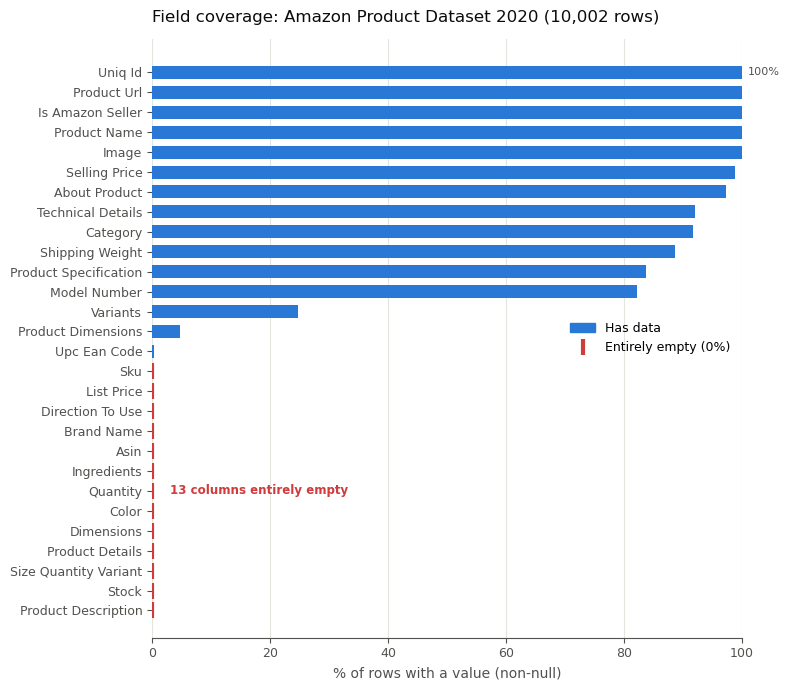

In [6]:
plot_cov = coverage.sort_values("non_null_pct")
has_data = plot_cov["non_null_pct"] > 0

fig, ax = plt.subplots(figsize=(8, 7))
ypos = range(len(plot_cov))
ax.barh(
    [y for y, v in zip(ypos, has_data) if v],
    plot_cov.loc[has_data, "non_null_pct"],
    color=BLUE, height=0.65, zorder=3,
)
# A 0%-length bar can't show a fill color, so empty columns get a visible marker
# at x=0 instead of an invisible zero-width bar.
empty_y = [y for y, v in zip(ypos, has_data) if not v]
ax.plot([0] * len(empty_y), empty_y, marker="|", markersize=11, markeredgewidth=3,
        linestyle="none", color=CRITICAL_RED, zorder=4)

ax.set_yticks(list(ypos))
ax.set_yticklabels(plot_cov.index)
ax.set_xlim(0, 100)
ax.set_xlabel("% of rows with a value (non-null)")
ax.set_title("Field coverage: Amazon Product Dataset 2020 (10,002 rows)",
             color=TEXT_PRIMARY, fontsize=12, loc="left", pad=12)
clean_ax(ax)

ax.text(101, ypos[-1], "100%", va="center", fontsize=8, color=TEXT_SECONDARY)
n_empty = len(empty_y)
ax.text(3, (min(empty_y) + max(empty_y)) / 2, f"{n_empty} columns entirely empty",
        va="center", fontsize=8.5, color=CRITICAL_RED, fontweight="bold")

legend_handles = [
    plt.Rectangle((0, 0), 1, 1, color=BLUE, label="Has data"),
    plt.Line2D([0], [0], marker="|", markersize=11, markeredgewidth=3,
               linestyle="none", color=CRITICAL_RED, label="Entirely empty (0%)"),
]
ax.legend(handles=legend_handles, loc="center right", frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

## Price distribution

`List Price` is 0% populated, so use `Selling Price` instead.

In [7]:
print("=" * 70)
print("PRICE DISTRIBUTION")
print("=" * 70)

for col in ["List Price", "Selling Price"]:
    non_null = df[col].notna().sum()
    print(f"{col}: {non_null:,} / {len(df):,} non-null ({non_null / len(df):.1%})")


def to_numeric_price(series: pd.Series) -> pd.Series:
    return pd.to_numeric(
        series.astype(str).str.replace(r"[^0-9.]", "", regex=True), errors="coerce"
    )


selling = to_numeric_price(df["Selling Price"])
print()
print("Selling Price stats (parsed numeric):")
print(selling.describe().round(2).to_string())

PRICE DISTRIBUTION
List Price: 0 / 10,002 non-null (0.0%)
Selling Price: 9,895 / 10,002 non-null (98.9%)

Selling Price stats (parsed numeric):
count    9524.00
mean       40.61
std       148.87
min         0.01
25%         9.99
50%        16.94
75%        29.99
max      5999.00


**Chart:** `Selling Price` distribution (log scale: the data spans $0.01 to
$5,999, heavily right-skewed). Median and mean marked directly on the plot.

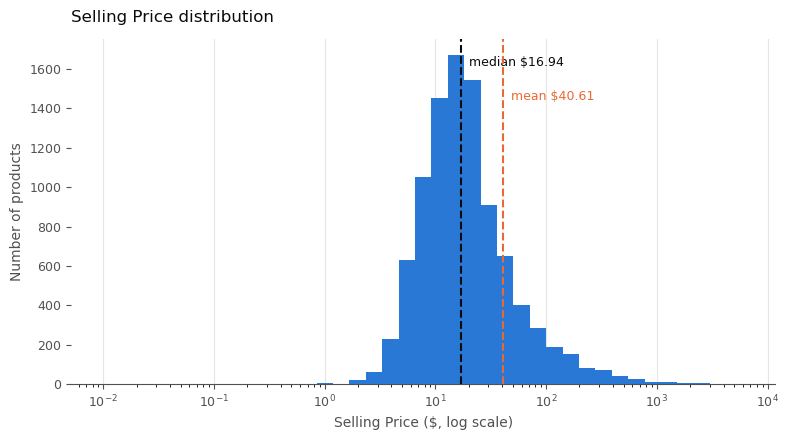

In [8]:
import numpy as np

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.logspace(np.log10(selling.min()), np.log10(selling.max()), 40)
ax.hist(selling.dropna(), bins=bins, color=BLUE, zorder=3)
ax.set_xscale("log")
ax.set_xlabel("Selling Price ($, log scale)")
ax.set_ylabel("Number of products")
ax.set_title("Selling Price distribution", color=TEXT_PRIMARY, fontsize=12,
             loc="left", pad=12)
clean_ax(ax)

median, mean = selling.median(), selling.mean()
ax.axvline(median, color=TEXT_PRIMARY, linewidth=1.5, linestyle="--", zorder=4)
ax.axvline(mean, color=ORANGE, linewidth=1.5, linestyle="--", zorder=4)
ymax = ax.get_ylim()[1]
ax.text(median, ymax * 0.95, f"  median ${median:.2f}", color=TEXT_PRIMARY,
        fontsize=9, va="top")
ax.text(mean, ymax * 0.85, f"  mean ${mean:.2f}", color=ORANGE, fontsize=9, va="top")

plt.tight_layout()
plt.show()

## Duplicate check

In [9]:
print("=" * 70)
print("DUPLICATE CHECK")
print("=" * 70)


def dup_count(col: str) -> str:
    non_null = df[col].dropna()
    if non_null.empty:
        return "n/a (column is entirely empty)"
    return f"{non_null.duplicated(keep=False).sum():,} (out of {len(non_null):,} non-null values)"


print(f"Duplicate Asin values: {dup_count('Asin')}")
print(f"Duplicate Uniq Id values: {dup_count('Uniq Id')}")
print(f"Duplicate Product Name values: {dup_count('Product Name')}")

DUPLICATE CHECK
Duplicate Asin values: n/a (column is entirely empty)
Duplicate Uniq Id values: 0 (out of 10,002 non-null values)
Duplicate Product Name values: 137 (out of 10,002 non-null values)


## Category distribution

Confirms `Home & Kitchen` as the demo category slice. `Household`/`Cleaning` combined is only
~25 rows, too sparse to use.

In [10]:
print("=" * 70)
print("CATEGORY DISTRIBUTION (top-level, from pipe-delimited Category field)")
print("=" * 70)
top_level = df["Category"].fillna("").str.split("|").str[0].str.strip()
counts = top_level.value_counts()
print(counts.head(15).to_string())

print("\nCandidate demo-category row counts:")
for cat in CANDIDATE_CATEGORIES:
    mask = df["Category"].fillna("").str.contains(cat, case=False)
    print(f"  '{cat}': {mask.sum():,} rows")

CATEGORY DISTRIBUTION (top-level, from pipe-delimited Category field)
Category
Toys & Games                                6662
                                             830
Home & Kitchen                               708
Clothing, Shoes & Jewelry                    630
Sports & Outdoors                            540
Baby Products                                214
Arts, Crafts & Sewing                        124
Office Products                               77
Hobbies                                       34
Industrial & Scientific                       29
Health & Household                            23
Remote & App Controlled Vehicle Parts         22
Tools & Home Improvement                      17
Remote & App Controlled Vehicles & Parts      17
Pet Supplies                                  16

Candidate demo-category row counts:
  'Home & Kitchen': 712 rows
  'Sports & Outdoors': 540 rows
  'Household': 23 rows
  'Cleaning': 2 rows


**Chart:** top 15 top-level categories by product count. Orange marks `Home &
Kitchen`, the recommended demo slice, against the `Toys & Games` majority and the
long tail everything else falls into.

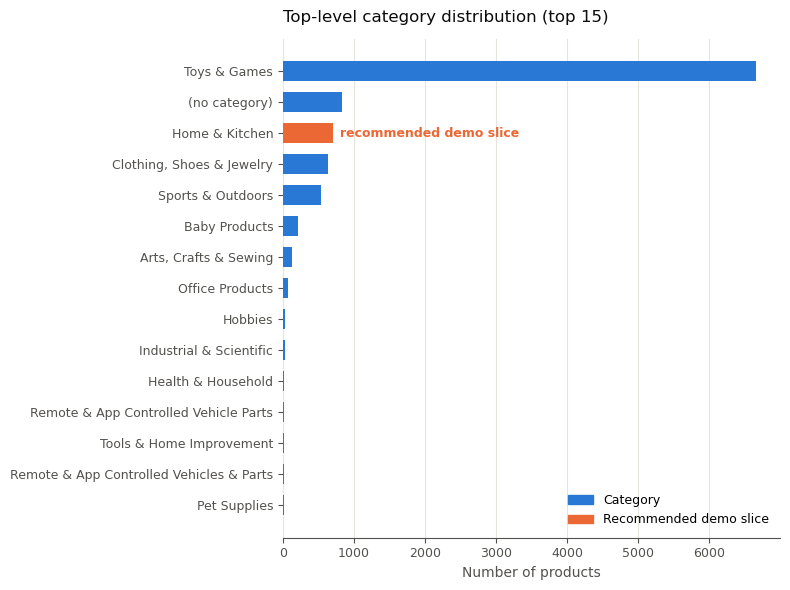

In [11]:
top15 = counts.head(15).rename(index={"": "(no category)"})
colors = [ORANGE if cat == "Home & Kitchen" else BLUE for cat in top15.index]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top15.index[::-1], top15.values[::-1], color=colors[::-1], height=0.65, zorder=3)
ax.set_xlabel("Number of products")
ax.set_title("Top-level category distribution (top 15)", color=TEXT_PRIMARY,
             fontsize=12, loc="left", pad=12)
clean_ax(ax)

hk_count = int(top15["Home & Kitchen"])
hk_y = list(top15.index[::-1]).index("Home & Kitchen")
ax.text(hk_count + 100, hk_y, "recommended demo slice", va="center",
        fontsize=9, color=ORANGE, fontweight="bold")

legend_handles = [
    plt.Rectangle((0, 0), 1, 1, color=BLUE, label="Category"),
    plt.Rectangle((0, 0), 1, 1, color=ORANGE, label="Recommended demo slice"),
]
ax.legend(handles=legend_handles, loc="lower right", frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

## Save the per-column coverage summary

Writes `Code/1. Data Pipeline & Indexing/processed/column_coverage.csv`.

In [12]:
os.makedirs(OUTPUT_DIR, exist_ok=True)
coverage.to_csv(COVERAGE_CSV)
print("Wrote:", COVERAGE_CSV)

Wrote: /Users/pareeyaporn/Desktop/ADSP 32028 Applied Generative AI - Agents and Multimodal Intelligence/Project/Code/1. Data Pipeline & Indexing/processed/column_coverage.csv


## Conclusion

This dataset has real gaps (several columns are empty and there's no rating field), and `Home & Kitchen` (our demo category) turned out to be mostly kids' products, not cookware. Full details: [data_schema_and_licensing.md](../../Project%20Overview/data_schema_and_licensing.md). Next: [1.2 process data.ipynb](1.2%20process%20data.ipynb).